# Loading the models

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error


TUNER_RESULTS_FOLDER = "../../data/tuner_results"
model_with_t = joblib.load(f"{TUNER_RESULTS_FOLDER}/with/refit_best_model.mod")
model_wout_t = joblib.load(f"{TUNER_RESULTS_FOLDER}/wout/refit_best_model.mod")

# Loading the catalogue data

In [2]:
CATALOG_PATH = "../../data/catalogue_data_021026.csv"

catalog = pd.read_csv(CATALOG_PATH)
catalog.dropna(how="all", axis=0, inplace=True)
catalog

,source,radio,association,class,distance(kpc),l(deg),b(deg),period(s),pdot(1e-11s/s),pdot_ul,...,Err_kT_min,kT_min_ul,lumin_peak,kT_max,Err_kT_max,kT_max_ul,Err_lum_down(1e33erg/s),Err_lum_up(1e33erg/s),Err_tau_real_down(kyr),Err_tau_real_up(kyr)
0,CXOUJ185238.6+0040,NaN,SNR Kes79,CCO,7.10,33.667347,0.038728,0.105,8.700000e-07,NaN,...,0.001,NaN,NaN,NaN,NaN,NaN,0.420,0.420,1.20,1.20
1,1E1207.4-5209,NaN,SNR G296.5+10.0,CCO,2.35,296.545164,9.916088,0.424,2.200000e-06,NaN,...,0.100,NaN,NaN,NaN,NaN,NaN,4.980,2.270,2.30,2.30
2,RXJ0822.0-4300,NaN,SNR PuppisA,CCO,1.30,260.572541,-3.495317,0.113,9.300000e-07,NaN,...,0.050,NaN,NaN,NaN,NaN,NaN,1.000,1.000,0.50,0.50
3,1E161348-5055,NaN,SNR RCW103,CCO,3.30,332.428951,-0.373763,24030.000,7.000000e+01,True,...,0.100,NaN,220.0,1.2,0.1,NaN,1.000,1.000,1.20,1.20
4,CXOJ085201.4-461753,NaN,SNR Vela Jr,CCO,0.77,266.234600,-1.194200,NaN,NaN,NaN,...,0.010,NaN,NaN,NaN,NaN,NaN,0.060,0.060,1.25,1.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,RXJ2143.0+0654,NaN,NaN,XDINS,0.43,62.657328,-33.139952,9.428,4.100000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
72,RXJ0720.4-3125,NaN,NaN,XDINS,0.29,244.158050,-8.164527,8.391,6.983000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.034,0.034,15.00,15.00
73,RXJ0806.4-4123,NaN,NaN,XDINS,0.25,257.426088,-4.984389,11.370,5.500000e-03,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
74,RXJ1308.6+2127,NaN,NaN,XDINS,0.50,338.745669,83.081296,10.310,1.100000e-02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.003,0.003,100.00,100.00


# Filter the data and apply the models

In [3]:
results = catalog.copy()

def lognnan(x):
    """Get the log10 of an array, returning NaN for non-finite values."""
    return np.where(np.isfinite(x), np.log10(x), np.nan)

results["logP_true"] = lognnan(catalog["period(s)"])
results["logPdot_true"] = lognnan(catalog["pdot(1e-11s/s)"] * 1.0e-11)
results["logL_true"] = lognnan(catalog["luminosity_bol_qui(e33erg/s)"] * 1.0e33)
results["logt_true"] = lognnan(catalog["tau_real(kyr)"] * 1.0e3)
results["logB_true"] = lognnan(catalog["Bp(e14G)"] * 1.0e14)

X = results.rename(
    columns={col: col.split("_true")[0] for col in results.columns})

X_scaled = model_wout_t.transformer.transform("X", X)
in_bounds = (X_scaled.min(axis=1) >= 0) & (X_scaled.max(axis=1) <= 1)
print(f"{sum(in_bounds)} sources with defined inputs, and in bounds "
      f"[{100*np.mean(in_bounds):.1f}%].")
results["in_bounds"] = in_bounds

X_scaled2 = model_with_t.transformer.transform("X", X)
in_bounds2 = (X_scaled2.min(axis=1) >= 0) & (X_scaled2.max(axis=1) <= 1)

assert not (~in_bounds & in_bounds2).any()

Y_reg_wout, Y_cls_wout = model_wout_t.predict(X)
Y_reg_wout.index = results.index
Y_cls_wout.index = results.index

Y_reg_with, Y_cls_with = model_with_t.predict(X)
Y_reg_with.index = results.index
Y_cls_with.index = results.index

Y_reg_with[~in_bounds2] = np.nan
Y_reg_wout[~in_bounds] = np.nan
Y_cls_with[~in_bounds2] = np.nan
Y_cls_wout[~in_bounds] = np.nan

wout_cols = {col: col + "_pred_wout"for col in Y_reg_wout.columns}
with_cols = {col: col + "_pred_with" for col in Y_reg_with.columns}
results = pd.concat([results, Y_reg_wout.rename(columns=wout_cols)],
                    axis=1, ignore_index=False)
results["envelope_wout"] = Y_cls_wout
results = pd.concat([results, Y_reg_with.rename(columns=with_cols)],
                    axis=1, ignore_index=False)
results["envelope_with"] = Y_cls_with

results.to_csv("../../results/catalog_results.csv", index_label="index")
results

51 sources with defined inputs, and in bounds [69.9%].


,source,radio,association,class,distance(kpc),l(deg),b(deg),period(s),pdot(1e-11s/s),pdot_ul,...,in_bounds,logB_pred_wout,M_pred_wout,logB0_pred_wout,logt_pred_wout,envelope_wout,logB_pred_with,M_pred_with,logB0_pred_with,envelope_with
0,CXOUJ185238.6+0040,NaN,SNR Kes79,CCO,7.10,33.667347,0.038728,0.105,8.700000e-07,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1E1207.4-5209,NaN,SNR G296.5+10.0,CCO,2.35,296.545164,9.916088,0.424,2.200000e-06,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RXJ0822.0-4300,NaN,SNR PuppisA,CCO,1.30,260.572541,-3.495317,0.113,9.300000e-07,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1E161348-5055,NaN,SNR RCW103,CCO,3.30,332.428951,-0.373763,24030.000,7.000000e+01,True,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CXOJ085201.4-461753,NaN,SNR Vela Jr,CCO,0.77,266.234600,-1.194200,NaN,NaN,NaN,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,RXJ2143.0+0654,NaN,NaN,XDINS,0.43,62.657328,-33.139952,9.428,4.100000e-03,NaN,...,True,13.426386,1.490177,14.380429,5.697321,1.0,NaN,NaN,NaN,NaN
72,RXJ0720.4-3125,NaN,NaN,XDINS,0.29,244.158050,-8.164527,8.391,6.983000e-03,NaN,...,True,13.505513,1.785344,14.341165,5.605628,1.0,13.546233,1.159809,14.057027,1.0
73,RXJ0806.4-4123,NaN,NaN,XDINS,0.25,257.426088,-4.984389,11.370,5.500000e-03,NaN,...,True,13.508372,1.141909,14.368550,5.807432,1.0,NaN,NaN,NaN,NaN
74,RXJ1308.6+2127,NaN,NaN,XDINS,0.50,338.745669,83.081296,10.310,1.100000e-02,NaN,...,True,13.646963,1.617019,14.438653,5.634496,1.0,NaN,NaN,NaN,NaN


In [4]:
# Envelope composition predicted for the observed sources, by both networks.
# The networks classify the envelope as heavy (H) or light (L). P(H) is the
# network's output probability for a heavy envelope (P(L) = 1 - P(H)); the
# predicted class is H when P(H) >= 0.5. Sources outside the input range of a
# network get no prediction from it (same bounds check as above).
def prob_heavy(model, X, ok):
    """Probability of a heavy envelope (env=H = 1) for each row of X."""
    _, prob = model.model.predict(model.transformer.transform("X", X), verbose=0)
    classes = list(model.transformer.y_cls_encoder.classes_)
    return np.where(ok, prob[:, classes.index(1)], np.nan)

results["P_H_wout"] = prob_heavy(model_wout_t, X, in_bounds)
results["P_H_with"] = prob_heavy(model_with_t, X, in_bounds2)
for m in ["wout", "with"]:
    p_h = results[f"P_H_{m}"]
    results[f"env_{m}"] = np.where(p_h.isna(), "", np.where(p_h >= 0.5, "H", "L"))

    ok = p_h.notna()
    assert ((p_h[ok] >= 0.5).astype(int) == results.loc[ok, f"envelope_{m}"].astype(int)).all()

env = results.loc[in_bounds, ["source", "class", "env_wout", "P_H_wout",
                              "env_with", "P_H_with"]].sort_values(["class", "source"])
env.to_csv("../../results/catalog_envelope.csv", index=False)

with pd.option_context("display.max_rows", None, "display.float_format", "{:.2f}".format):
    print(env.to_string(index=False))

# Number of heavy / light envelopes per class
for m in ["wout", "with"]:
    print(f"\n{m} network:")
    print(pd.crosstab(env["class"], env[f"env_{m}"].replace("", "no prediction")))

            source    class env_wout  P_H_wout env_with  P_H_with
     1E1048.1-5937 Magnetar        L      0.00                NaN
       1E1547-5408 Magnetar        H      1.00        H      0.99
        1E1841-045 Magnetar        L      0.00        L      0.01
        1E2259+586 Magnetar        L      0.00        L      0.00
1RXSJ170849.0-4009 Magnetar        L      0.00                NaN
    3XMMJ1852+0033 Magnetar        L      0.00                NaN
        4U0142+614 Magnetar        L      0.00                NaN
 CXOUJ010043.1-721 Magnetar        L      0.00                NaN
    CXOUJ1647-4552 Magnetar        L      0.47                NaN
CXOUJ171405.7-3810 Magnetar        L      0.37        L      0.00
     PSRJ1119-6127 Magnetar        H      0.71        H      1.00
     PSRJ1622-4950 Magnetar        H      1.00                NaN
        SGR0526-66 Magnetar        L      0.00        L      0.01
        SGR1627-41 Magnetar        H      1.00        H      1.00
        SG

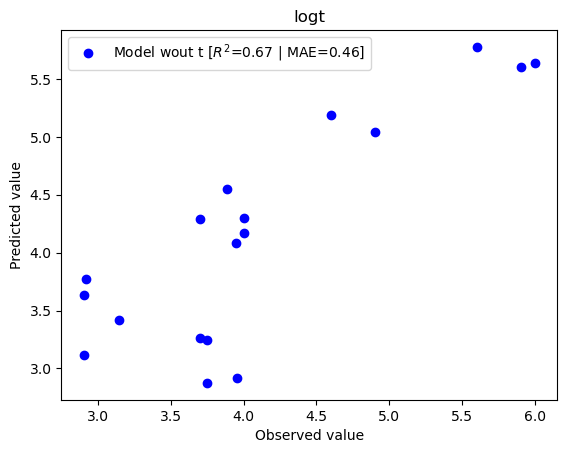

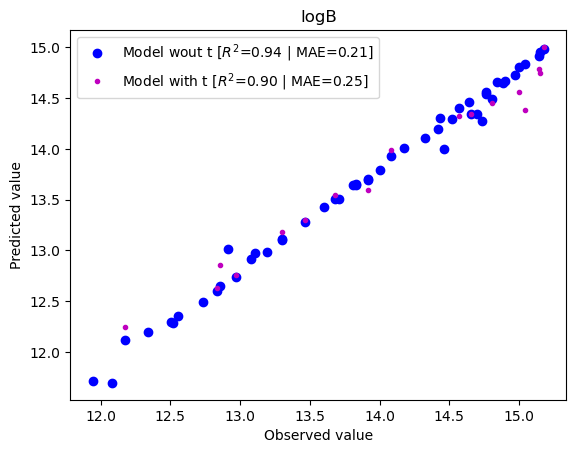

In [5]:

for obs_col in results.columns:
    if not obs_col.endswith("_true"):
        continue
    observed = results[obs_col]

    col = obs_col.split("_true")[0]
    col_wout, col_with  = [col + suffix for suffix in ["_pred_wout", "_pred_with"]]
    if col_with not in results.columns and col_wout not in results.columns:
        continue

    plt.figure()
    plt.title(col)
    plt.xlabel("Observed value")
    plt.ylabel("Predicted value")
    for pred_col, model_label, color in zip([col_wout, col_with],
                                            ["Model wout t", "Model with t"],
                                            ["b", "m"]):
        if pred_col in results.columns:
            predicted = results[pred_col]

            ok = np.isfinite(observed + predicted)
            r2 = r2_score(observed[ok], predicted[ok])
            mae = mean_absolute_error(observed[ok], predicted[ok])
            label = f"{model_label} [$R^2$={r2:.2f} | MAE={mae:.2f}]"
            plt.plot(observed[ok], predicted[ok],
                     "o" if color=="b" else ".", color=color, label=label)
    plt.legend(loc="best")
    plt.show()

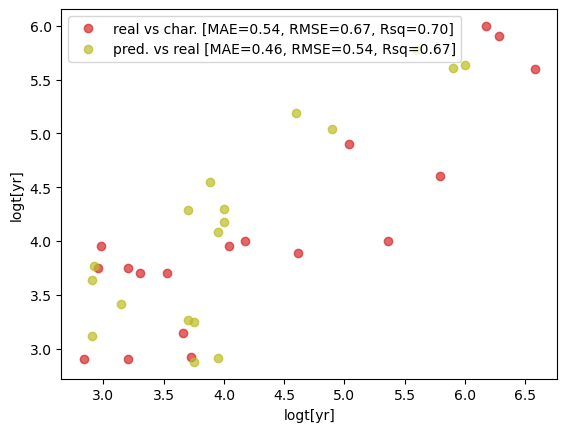

In [6]:
plt.figure()
logt_c = np.log10(results["tau_c(kyr)"] * 1000)
logt = results["logt_true"].copy()
logt_pred = results["logt_pred_wout"].copy()
ok = np.isfinite(logt + logt_pred + logt_c)
logt, logt_pred, logt_c = logt[ok], logt_pred[ok], logt_c[ok]

def mae_str(x, y):
    """Get the mean absolute error string for two arrays."""
    maerr = np.mean(np.abs(x - y))
    rmse = np.sqrt(np.mean((x-y)**2.0))
    mr = r2_score(x, y)
    return f" [MAE={maerr:.2f}, RMSE={rmse:.2f}, Rsq={mr:.2f}]"

plt.plot(logt_c, logt, "o", color="C3", alpha=0.7,
         label="real vs char." + mae_str(logt_c, logt))
plt.plot(logt, logt_pred, "o", color="C8", alpha=0.7,
         label="pred. vs real" + mae_str(logt, logt_pred))
plt.legend(loc="upper left")
plt.xlabel("logt[yr]")
plt.ylabel("logt[yr]")
plt.show()


N = 18
tau_real <= tau_c: 12 of 18; exceptions: SGR1627-41, 1E1547-5408, SGR1900+14, CXOUJ171405.7-3810, SGR0526-66, PSRJ1119-6127
tau_real - error <= tau_c: 12 of 18; exceptions: SGR1627-41, 1E1547-5408, SGR1900+14, CXOUJ171405.7-3810, SGR0526-66, PSRJ1119-6127
No uncertainty on the real age: 1E1547-5408
MAE tau_c: 0.54 dex (real ages as given); 0.55 (+0.03/-0.03) with their uncertainties
MAE NN:    0.46 dex (real ages as given); 0.47 (+0.03/-0.03) with their uncertainties
Fraction of draws with MAE NN < MAE tau_c: 1.00


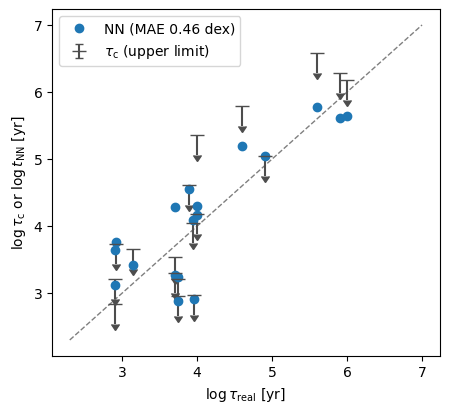

In [7]:
# Age test. The characteristic age tau_c = P / (2 Pdot) is taken as an upper limit
# on the real age (no uncertainty on tau_c): it overestimates the real age when the
# field decays or when the birth period is close to the present one.
# Two versions: real ages as given, and real ages with their uncertainties.
N_MC = 20000              # random draws of the real ages (MAE uncertainty)

logt_c = np.log10(results["tau_c(kyr)"] * 1e3)
ok = np.isfinite(results["logt_true"] + results["logt_pred_wout"] + logt_c)
age = results.loc[ok, ["source", "class", "tau_c(kyr)", "tau_real(kyr)",
                       "Err_tau_real_down(kyr)", "Err_tau_real_up(kyr)",
                       "logt_true", "logt_pred_wout"]].copy()
age["logt_c"] = logt_c[ok]
t_r = age["tau_real(kyr)"].values
e_lo = age["Err_tau_real_down(kyr)"].fillna(0).values      # no error given -> 0
e_hi = age["Err_tau_real_up(kyr)"].fillna(0).values
t_c = age["tau_c(kyr)"].values

# consistency with tau_c being an upper limit
age["ok_noerr"] = t_r <= t_c                    # real age as given
age["ok_err"] = (t_r - e_lo) <= t_c             # real age within its uncertainty
print(f"N = {len(age)}")
print(f"tau_real <= tau_c: {age['ok_noerr'].sum()} of {len(age)}; "
      f"exceptions: {', '.join(age.loc[~age['ok_noerr'], 'source'])}")
print(f"tau_real - error <= tau_c: {age['ok_err'].sum()} of {len(age)}; "
      f"exceptions: {', '.join(age.loc[~age['ok_err'], 'source'])}")
print("No uncertainty on the real age:", ", ".join(age.loc[e_lo + e_hi == 0, "source"]))

# MAE of tau_c and of the network against the real age. tau_c enters here as an
# age estimate (not as a limit).
mae = lambda pred, true: np.mean(np.abs(pred - true), axis=-1)
mae_c0 = mae(age["logt_c"].values, age["logt_true"].values)
mae_p0 = mae(age["logt_pred_wout"].values, age["logt_true"].values)

# Same MAE with the real ages drawn from two-sided Gaussians (Err_down / Err_up),
# truncated at zero; sources without uncertainties keep their value.
rng = np.random.default_rng(31337)
draw = np.empty((N_MC, len(t_r)))
for j in range(len(t_r)):
    x = np.empty(0)
    while x.size < N_MC:
        z = rng.standard_normal(2 * N_MC)
        y = t_r[j] + np.where(z < 0, z * e_lo[j], z * e_hi[j])
        x = np.concatenate([x, y[y > 0]])
    draw[:, j] = x[:N_MC]
logt_draw = np.log10(draw * 1e3)
mae_c_mc = mae(age["logt_c"].values, logt_draw)
mae_p_mc = mae(age["logt_pred_wout"].values, logt_draw)
pc = lambda x: np.percentile(x, [16, 50, 84])
c16, c50, c84 = pc(mae_c_mc)
p16, p50, p84 = pc(mae_p_mc)
print(f"MAE tau_c: {mae_c0:.2f} dex (real ages as given); "
      f"{c50:.2f} (+{c84 - c50:.2f}/-{c50 - c16:.2f}) with their uncertainties")
print(f"MAE NN:    {mae_p0:.2f} dex (real ages as given); "
      f"{p50:.2f} (+{p84 - p50:.2f}/-{p50 - p16:.2f}) with their uncertainties")
print(f"Fraction of draws with MAE NN < MAE tau_c: {np.mean(mae_p_mc < mae_c_mc):.2f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([2.3, 7], [2.3, 7], "k--", lw=1, alpha=0.5)
ax.errorbar(age["logt_true"], age["logt_c"], yerr=0.3, uplims=True, fmt="_",
            color="0.3", ms=10, label=r"$\tau_{\rm c}$ (upper limit)")
ax.plot(age["logt_true"], age["logt_pred_wout"], "o", color="C0",
        label=f"NN (MAE {mae_p0:.2f} dex)")
ax.set_xlabel(r"$\log\tau_{\rm real}$ [yr]")
ax.set_ylabel(r"$\log\tau_{\rm c}$ or $\log t_{\rm NN}$ [yr]")
ax.legend(loc="upper left")
plt.show()

# Manuscript figures
Age test, predicted masses and predicted envelopes (main text); B check (appendix). PDFs are saved in `../../figures/`.

In [8]:
import os
FIG_DIR = "../../figures/"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"font.size": 10, "xtick.direction": "in", "ytick.direction": "in"})
STY = {"Magnetar": ("#D55E00", "o"), "RPP": ("#0072B2", "D"),
       "XDINS": ("#009E73", "s"), "CCO": ("#CC79A7", "^")}
M_LO, M_HI = 1.3, 1.9          # mass range of the training simulations [Msun]
import matplotlib.patheffects as pe
# white outline so the with-age bar stays visible on top of the wout symbol
HALO = [pe.withStroke(linewidth=3.2, foreground="white")]

import re
COL_W = 3.45                   # column width [inch]
NAME_FS = 7                    # font size of the source names
_PREFIX = re.compile(r"^(SGR|PSR|CXOU|CXO|1RXS|RX|3XMM|2XMM|XMMU|XTE|Swift|1WGA|1E|4U)(.+)$")
def pretty(name):
    """'SGR1627-41' -> 'SGR 1627−41' (space after the prefix, true minus sign)."""
    m = _PREFIX.match(name)
    if m:
        name = f"{m.group(1)} {m.group(2)}"
    return name.replace("-", "−")

fr = results[results["source"].notna()].copy()
# sources whose luminosity or Pdot is only an upper limit
fr["is_ul"] = (fr["lum_ul"] == True) | (fr["pdot_ul"] == True)

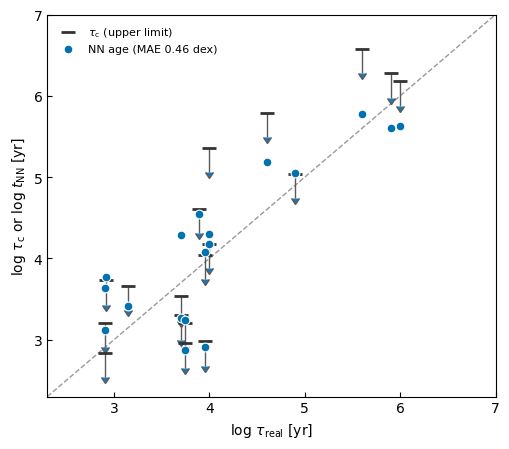

fig_age_test.pdf: 12 of 18 sources with tau_real <= tau_c


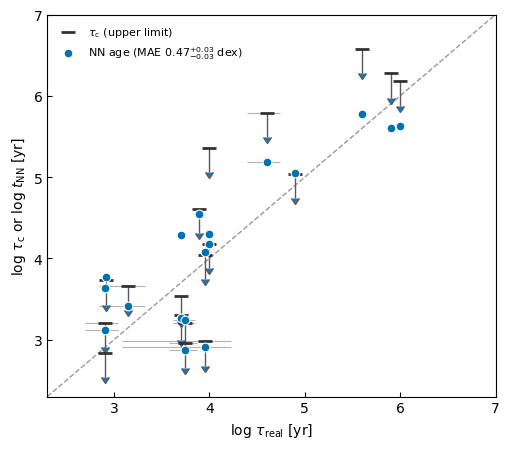

fig_age_test_err.pdf: 12 of 18 sources with tau_real <= tau_c


In [9]:
def fig_age_test(with_err, out):
    x = age["logt_true"].values
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    lims = [2.3, 7.0]
    ax.plot(lims, lims, color="0.6", ls="--", lw=1, zorder=0)

    if with_err:   # horizontal bars: uncertainty on the real age (log scale)
        lo = x - np.log10(np.clip(t_r - e_lo, 1e-3, None) * 1e3)
        hi = np.log10((t_r + e_hi) * 1e3) - x
        for y in (age["logt_c"], age["logt_pred_wout"]):
            ax.errorbar(x, y, xerr=[lo, hi], fmt="none", ecolor="0.7", lw=0.8, zorder=1)

    # tau_c: treated as upper limit on the age
    ax.errorbar(x, age["logt_c"], yerr=0.3, uplims=True, fmt="none", ecolor="0.35",
                lw=1, zorder=1)
    ax.scatter(x, age["logt_c"], marker="_", s=90, color="0.2", lw=2, zorder=2,
               label=r"$\tau_{\rm c}$ (upper limit)")

    # network
    if with_err:
        lab = (rf"NN age (MAE ${p50:.2f}^{{+{p84 - p50:.2f}}}_{{-{p50 - p16:.2f}}}$ dex)")
    else:
        lab = rf"NN age (MAE {mae_p0:.2f} dex)"
    ax.scatter(x, age["logt_pred_wout"], s=40, color="#0072B2", edgecolor="white",
               lw=0.8, zorder=3, label=lab)

    # sources with tau_real > tau_c (inconsistent with the upper limit)
    viol = ~age["ok_err"] if with_err else ~age["ok_noerr"]

    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel(r"$\log\,\tau_{\rm real}$ [yr]")
    ax.set_ylabel(r"$\log\,\tau_{\rm c}$ or $\log\,t_{\rm NN}$ [yr]")
    ax.legend(loc="upper left", fontsize=8, frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, out))
    plt.show()
    print(f"{out}: {(~viol).sum()} of {len(age)} sources with tau_real <= tau_c")

fig_age_test(with_err=False, out="fig_age_test.pdf")
fig_age_test(with_err=True, out="fig_age_test_err.pdf")

Masses outside the training range 1.3-1.9 Msun: 19 of 51
Masses outside the physical range 1.1-2.28 Msun: 7 of 51


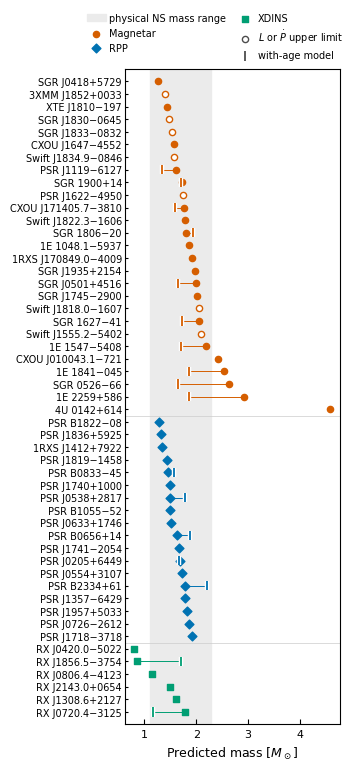

In [10]:
M_PHYS_LO = 1.1    # minimum NS mass from core collapse (Suwa et al. 2018)
M_PHYS_HI = 2.28   # maximum mass for BSk24 (Pearson et al. 2018)

order = ["Magnetar", "RPP", "XDINS"]
p = fr[fr["M_pred_wout"].notna()].copy()
p["cls_i"] = p["class"].map({c: i for i, c in enumerate(order)})
p = p.sort_values(["cls_i", "M_pred_wout"]).reset_index(drop=True)
ood = p[(p["M_pred_wout"] < M_LO) | (p["M_pred_wout"] > M_HI)]
print(f"Masses outside the training range {M_LO}-{M_HI} Msun: {len(ood)} of {len(p)}")
unphys = p[(p["M_pred_wout"] < M_PHYS_LO) | (p["M_pred_wout"] > M_PHYS_HI)]
print(f"Masses outside the physical range {M_PHYS_LO}-{M_PHYS_HI} Msun: {len(unphys)} of {len(p)}")

fig, ax = plt.subplots(figsize=(COL_W, 7.6), layout="constrained")
ax.axvspan(M_PHYS_LO, M_PHYS_HI, color="0.92", zorder=0, label="physical NS mass range")
y = np.arange(len(p))[::-1]
for i, s in p.iterrows():
    c, m = STY[s["class"]]
    ax.scatter(s["M_pred_wout"], y[i], marker=m, s=20, zorder=3,
               facecolor="white" if s["is_ul"] else c, edgecolor=c, lw=1.0)
    if np.isfinite(s["M_pred_with"]):
        ax.plot([s["M_pred_wout"], s["M_pred_with"]], [y[i]] * 2, color=c, lw=0.7, zorder=2)
        ax.scatter(s["M_pred_with"], y[i], marker="|", s=45, color=c, lw=1.3, zorder=5,
                   path_effects=HALO)

for k in np.flatnonzero(np.diff(p["cls_i"].values)):
    ax.axhline(y[k] - 0.5, color="0.8", lw=0.5, zorder=1)
    
ax.set_yticks(y); ax.set_yticklabels([pretty(n) for n in p["source"]], fontsize=NAME_FS)
ax.tick_params(axis="y", length=2, pad=2)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylim(-1, len(p))
ax.set_xlabel(r"Predicted mass [$M_\odot$]", fontsize=9)
for c in order:
    ax.scatter([], [], marker=STY[c][1], color=STY[c][0], s=20, label=c)
ax.scatter([], [], marker="o", facecolor="white", edgecolor="0.3", s=20, label=r"$L$ or $\dot P$ upper limit")
ax.scatter([], [], marker="|", s=45, color="0.3", lw=1.3, label="with-age model")
ax.legend(loc="lower center", bbox_to_anchor=(0.42, 1.0), ncol=2, fontsize=7,
          frameon=False, handletextpad=0.3, columnspacing=1.0)
fig.savefig(os.path.join(FIG_DIR, "fig_mass_predictions.pdf"))
plt.show()

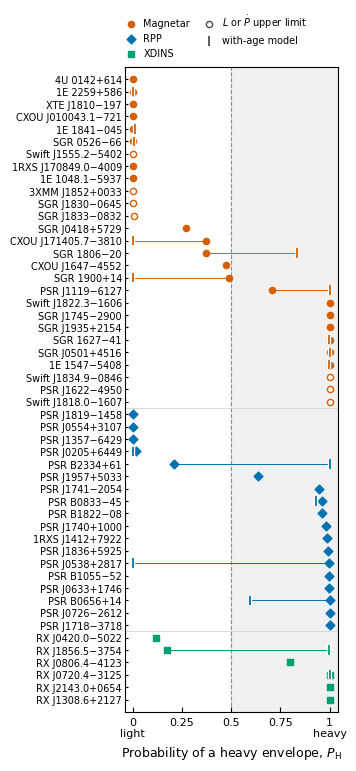

wout: 27 heavy, 24 light of 51; with: 10 heavy, 7 light of 17


In [11]:
order = ["Magnetar", "RPP", "XDINS"]
e = fr[fr["P_H_wout"].notna()].copy()
e["cls_i"] = e["class"].map({c: i for i, c in enumerate(order)})
e = e.sort_values(["cls_i", "P_H_wout"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(COL_W, 7.6), layout="constrained")
ax.axvspan(0.5, 1.05, color="0.94", zorder=0)            # heavy side
ax.axvline(0.5, color="0.55", ls="--", lw=0.8, zorder=1)
y = np.arange(len(e))[::-1]
for i, s in e.iterrows():
    c, m = STY[s["class"]]
    if np.isfinite(s["P_H_with"]):
        ax.plot([s["P_H_wout"], s["P_H_with"]], [y[i]] * 2, color=c, lw=0.7, zorder=2)
        ax.scatter(s["P_H_with"], y[i], marker="|", s=45, color=c, lw=1.3, zorder=5,
                   path_effects=HALO)
    ax.scatter(s["P_H_wout"], y[i], marker=m, s=20, zorder=4,
               facecolor="white" if s["is_ul"] else c, edgecolor=c, lw=1.0)

for k in np.flatnonzero(np.diff(e["cls_i"].values)):
    ax.axhline(y[k] - 0.5, color="0.8", lw=0.5, zorder=1)

ax.set_yticks(y); ax.set_yticklabels([pretty(n) for n in e["source"]], fontsize=NAME_FS)
ax.tick_params(axis="y", length=2, pad=2)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylim(-1, len(e))
ax.set_xlim(-0.04, 1.04)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.set_xticklabels(["0\nlight", "0.25", "0.5", "0.75", "1\nheavy"])
ax.set_xlabel(r"Probability of a heavy envelope, $P_{\rm H}$", fontsize=9)
for c in order:
    ax.scatter([], [], marker=STY[c][1], color=STY[c][0], s=20, label=c)
ax.scatter([], [], marker="o", facecolor="white", edgecolor="0.3", s=20, label=r"$L$ or $\dot P$ upper limit")
ax.scatter([], [], marker="|", s=45, color="0.3", lw=1.3, label="with-age model")
ax.legend(loc="lower center", bbox_to_anchor=(0.42, 1.0), ncol=2, fontsize=7,
          frameon=False, handletextpad=0.3, columnspacing=1.0)
fig.savefig(os.path.join(FIG_DIR, "fig_envelope_predictions.pdf"))
plt.show()
n_h = (e["P_H_wout"] >= 0.5).sum()
print(f"wout: {n_h} heavy, {len(e) - n_h} light of {len(e)}; "
      f"with: {(e['P_H_with'] >= 0.5).sum()} heavy, {(e['P_H_with'] < 0.5).sum()} light "
      f"of {e['P_H_with'].notna().sum()}")

N = 51; mean offset = -0.21 dex; std = 0.08 dex


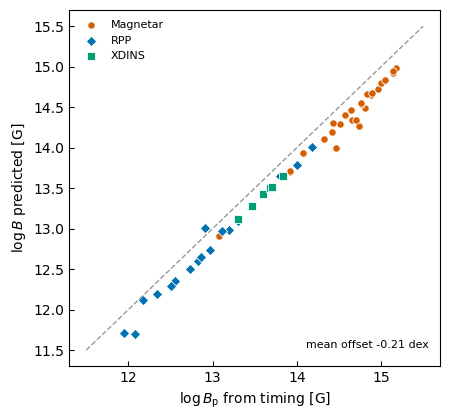

In [12]:
q = fr[np.isfinite(fr["logB_true"] + fr["logB_pred_wout"])]
d = q["logB_pred_wout"] - q["logB_true"]
print(f"N = {len(q)}; mean offset = {d.mean():+.2f} dex; std = {d.std():.2f} dex")

fig, ax = plt.subplots(figsize=(4.6, 4.3))
ax.plot([11.5, 15.5], [11.5, 15.5], color="0.6", ls="--", lw=1)
for c in ["Magnetar", "RPP", "XDINS"]:
    s = q[q["class"] == c]
    ax.scatter(s["logB_true"], s["logB_pred_wout"], marker=STY[c][1], color=STY[c][0],
               s=28, edgecolor="white", lw=0.6, label=c)
ax.set_xlabel(r"$\log B_{\rm p}$ from timing [G]")
ax.set_ylabel(r"$\log B$ predicted [G]")
ax.text(0.97, 0.05, f"mean offset {d.mean():+.2f} dex", transform=ax.transAxes,
        ha="right", fontsize=8)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_B_check.pdf"))
plt.show()
